# Ludlow vs Zhao host concentration — single-tree test (S13.2, `tree_13.2_33`)

One unevolved SatGen tree (`data/local_trees/unevolved_massspec/tree_13.2_33.npz`, logM0 = 13.2) evolved twice with `SatGen/src/jsm_SubEvo.py` at the fiducial settings (`alpha_type='conc'`, `lnL_pref=0.75`, `arbres`, `phi_res=1e-4`, seed 42 for both):

- **zhao** — the tree as generated: host c(z) from Zhao+09 (`gh.c2_Zhao09` via `init.c2_fromMAH`).
- **ludlow** — identical tree; only the host row `concentration[0,:]` replaced by the Ludlow+2016 c(z), computed at every snapshot from the host's full **collapsed mass history** (all distinct progenitors > f·M(z), tree re-rooted at each snapshot), f = 0.02, C = 400 (L16 Sec. 4.3 fn. 7, Parkinson+08-style trees). `SatGen/src/ludlow.py::concentration_history_Ludlow2016`.

All subhalo concentrations stay Zhao, and the TreeGen orbit initial conditions are shared, so branch *i* is the same subhalo in both runs. Because `alpha_type='conc'`, the host c enters both the potential and the stripping efficiency.

Inputs built by `src/ludlow_host_test/build_ludlow_tree.py`, evolved by `src/ludlow_host_test/run_evolve.py`; outputs in `data/ludlow_host_test/`. z=0 abundances follow the `ProcessH5` defaults: regime `"artificial"`, Nsub over all orders, fsub from k1 (inclusive masses), `mass_threshold = 6.75e9` (as in `run_fid.py`).

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.simplefilter("ignore")

sys.path.insert(0, '/Users/jsmonzon/Research/SatGen/mcmc/src/')
sys.path.insert(0, '/Users/jsmonzon/Research/SatGen/src/')
import jsm_stellarhalo

plt.style.use('../../../SatGen/notebooks/paper1/paper.mplstyle')

datadir = '../../data/ludlow_host_test/'
tag = '13.2_33'
mass_cut = 6.75e9
models = ['zhao', 'ludlow']
colors = {'zhao': 'steelblue', 'ludlow': 'darkorange'}

In [2]:
T = {m: jsm_stellarhalo.Tree_Reader(file=f'{datadir}tree_{tag}_{m}_evo.npz',
                                    mass_threshold=mass_cut, verbose=False)
     for m in models}
hist = np.load(f'{datadir}ludlow_host_history_{tag}.npz')

zt, lt = T['zhao'], T['ludlow']
# the two runs must share every accretion-time quantity (only the host c differs)
assert np.array_equal(zt.acc_mass, lt.acc_mass)
assert np.array_equal(zt.proper_acc_index, lt.proper_acc_index)
print('host logM0 = %.3f, z50 = %.2f, Nbranch = %d' % (np.log10(zt.mass[0,0]), zt.host_z50, zt.Nhalo))

host logM0 = 13.200, z50 = 0.58, Nbranch = 2589


## 1. Host concentration history

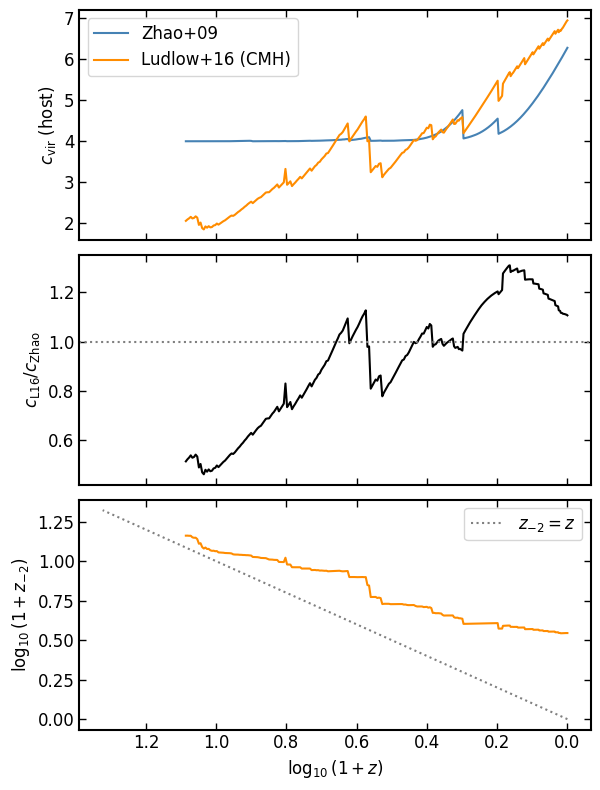

In [3]:
z = hist['redshift']
cz = np.where(hist['c_zhao'] > 0, hist['c_zhao'], np.nan)
cl = np.where(hist['c_ludlow'] > 0, hist['c_ludlow'], np.nan)
x = np.log10(1 + z)

fig, ax = plt.subplots(3, 1, figsize=(6, 8), sharex=True)
ax[0].plot(x, cz, color=colors['zhao'], label='Zhao+09')
ax[0].plot(x, cl, color=colors['ludlow'], label='Ludlow+16 (CMH)')
ax[0].set_ylabel(r'$c_{\rm vir}$ (host)')
ax[0].legend()

ax[1].plot(x, cl / cz, color='k')
ax[1].axhline(1, ls=':', color='grey')
ax[1].set_ylabel(r'$c_{\rm L16}/c_{\rm Zhao}$')

ax[2].plot(x, np.log10(1 + hist['z_m2']), color=colors['ludlow'])
ax[2].plot(x, x, ls=':', color='grey', label=r'$z_{-2}=z$')
ax[2].set_ylabel(r'$\log_{10}(1+z_{-2})$')
ax[2].set_xlabel(r'$\log_{10}(1+z)$')
ax[2].legend()

ax[2].invert_xaxis()   # time increases to the right
plt.tight_layout()
# plt.savefig('../../figures/ludlow_host_c_history.pdf', bbox_inches='tight')  # uncomment to save
plt.show()

## 2. Host potential at a few epochs

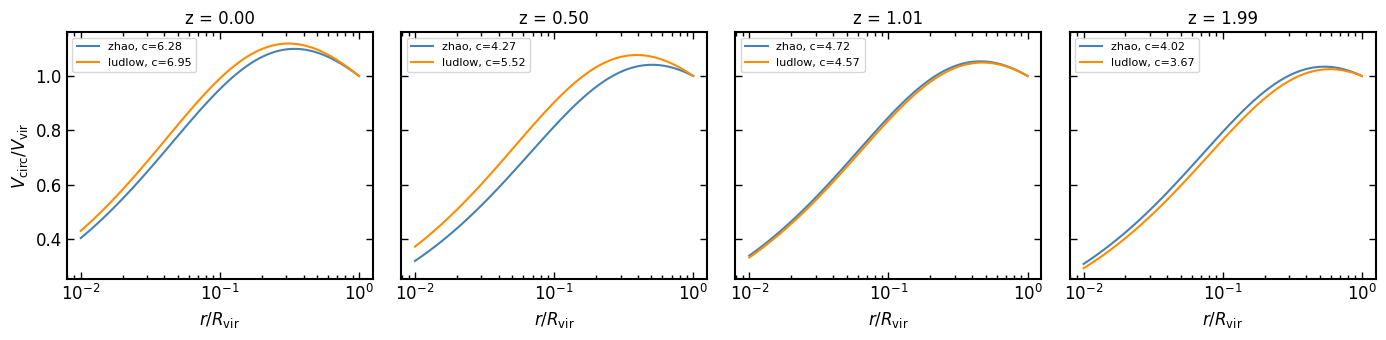

In [4]:
z_show = [0, 0.5, 1, 2]
fig, ax = plt.subplots(1, len(z_show), figsize=(14, 3.5), sharey=True)
for a, zs in zip(ax, z_show):
    iz = np.argmin(np.abs(zt.redshift - zs))
    for m in models:
        p = T[m].host_profiles[iz]
        r = np.logspace(-2, 0, 100) * p.rh
        a.plot(r / p.rh, p.Vcirc(r) / p.Vcirc(p.rh), color=colors[m],
               label=f'{m}, c={T[m].concentration[0, iz]:.2f}')
    a.set_xscale('log')
    a.set_title(f'z = {zt.redshift[iz]:.2f}')
    a.set_xlabel(r'$r/R_{\rm vir}$')
    a.legend(fontsize=8)
ax[0].set_ylabel(r'$V_{\rm circ}/V_{\rm vir}$')
plt.tight_layout()
# plt.savefig('../../figures/ludlow_host_Vcirc.pdf', bbox_inches='tight')  # uncomment to save
plt.show()

## 3. z = 0 abundances

In [5]:
rows = []
for regime in ['surviving', 'rvir_surv', 'artificial']:
    for m in models:
        t = T[m]
        rows.append({'regime': regime, 'model': m,
                     'Nsub': int(t.Nsub[regime][t.NSUB_ROWS['all'], 0]),
                     'fsub (k1)': t.fsub[regime][t.MSUB_ROWS['k1'], 0],
                     'max Msub/Mhost': t.max_msub_z0[regime] / t.mass[0, 0]})
pd.DataFrame(rows).set_index(['regime', 'model']).round(4)

Nsub  fsub (k1)  max Msub/Mhost
regime     model                                  
surviving  zhao      58     0.1851          0.0489
           ludlow    56     0.1788          0.0473
rvir_surv  zhao      32     0.1136          0.0489
           ludlow    31     0.1087          0.0473
artificial zhao      29     0.1111          0.0489
           ludlow    29     0.1053          0.0473

## 4. Subhalo-by-subhalo: how much more/less each subhalo is stripped

k1 subhaloes: 362
  survive (fb > 1e-4) in zhao: 336, ludlow: 331, both: 331, zhao-only: 5, ludlow-only: 0


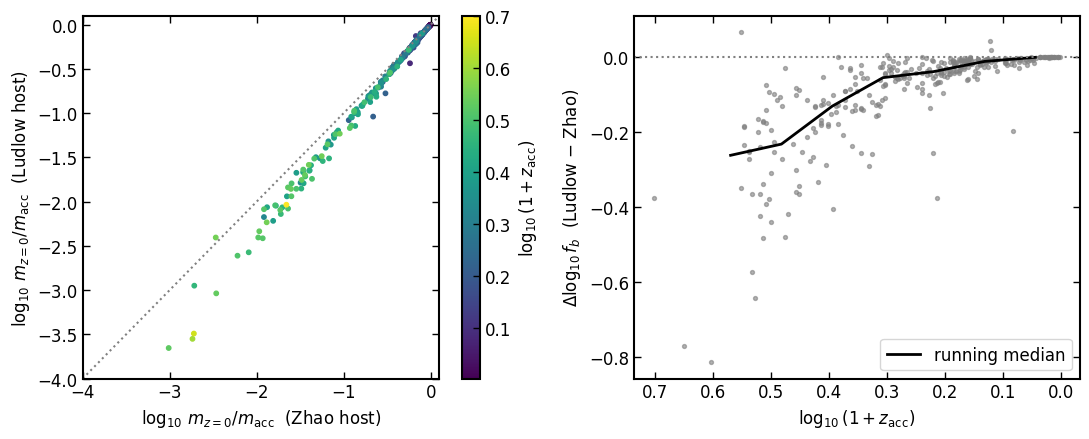

median dlog fb = -0.039 (16-84: -0.181, -0.007), N = 331


In [6]:
k1 = (zt.acc_order == 1)
k1[0] = False
surv_z = zt.valid_fbs[:, 0]
surv_l = lt.valid_fbs[:, 0]
fb_z = zt.mass[:, 0] / zt.acc_mass
fb_l = lt.mass[:, 0] / lt.acc_mass
zacc = zt.proper_acc_redshift

print('k1 subhaloes: %d' % k1.sum())
print('  survive (fb > 1e-4) in zhao: %d, ludlow: %d, both: %d, zhao-only: %d, ludlow-only: %d'
      % ((k1 & surv_z).sum(), (k1 & surv_l).sum(), (k1 & surv_z & surv_l).sum(),
         (k1 & surv_z & ~surv_l).sum(), (k1 & ~surv_z & surv_l).sum()))

both = k1 & surv_z & surv_l
dlogfb = np.log10(fb_l[both]) - np.log10(fb_z[both])

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
sc = ax[0].scatter(np.log10(fb_z[both]), np.log10(fb_l[both]), c=np.log10(1 + zacc[both]),
                   s=10, cmap='viridis')
lim = [-4, 0.1]
ax[0].plot(lim, lim, ls=':', color='grey')
ax[0].set_xlim(lim); ax[0].set_ylim(lim)
ax[0].set_xlabel(r'$\log_{10}\, m_{z=0}/m_{\rm acc}$  (Zhao host)')
ax[0].set_ylabel(r'$\log_{10}\, m_{z=0}/m_{\rm acc}$  (Ludlow host)')
plt.colorbar(sc, ax=ax[0], label=r'$\log_{10}(1+z_{\rm acc})$')

xa = np.log10(1 + zacc[both])
ax[1].scatter(xa, dlogfb, s=8, color='grey', alpha=0.6)
bins = np.linspace(0, xa.max(), 9)
idx = np.digitize(xa, bins)
med = [np.median(dlogfb[idx == i]) if (idx == i).sum() > 3 else np.nan for i in range(1, len(bins))]
ax[1].plot(0.5 * (bins[1:] + bins[:-1]), med, color='k', lw=2, label='running median')
ax[1].axhline(0, ls=':', color='grey')
ax[1].set_xlabel(r'$\log_{10}(1+z_{\rm acc})$')
ax[1].set_ylabel(r'$\Delta \log_{10} f_b$  (Ludlow $-$ Zhao)')
ax[1].invert_xaxis()   # time increases to the right
ax[1].legend()
plt.tight_layout()
# plt.savefig('../../figures/ludlow_host_paired_fb.pdf', bbox_inches='tight')  # uncomment to save
plt.show()

print('median dlog fb = %.3f (16-84: %.3f, %.3f), N = %d' % (np.median(dlogfb), *np.percentile(dlogfb, [16, 84]), both.sum()))

## 5. Nsub(z) and fsub(z) of the host

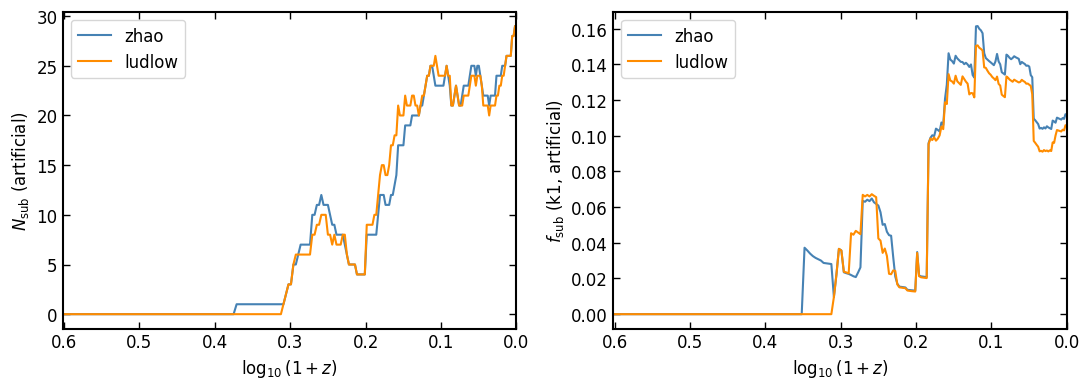

In [7]:
regime = 'artificial'
x = np.log10(1 + zt.redshift)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for m in models:
    t = T[m]
    ax[0].plot(x, t.Nsub[regime][t.NSUB_ROWS['all']], color=colors[m], label=m)
    ax[1].plot(x, t.fsub[regime][t.MSUB_ROWS['k1']], color=colors[m], label=m)
ax[0].set_ylabel(r'$N_{\rm sub}$ (' + regime + ')')
ax[1].set_ylabel(r'$f_{\rm sub}$ (k1, ' + regime + ')')
for a in ax:
    a.set_xlabel(r'$\log_{10}(1+z)$')
    a.set_xlim(np.log10(1 + 3), 0)   # reversed: time increases to the right
    a.legend()
plt.tight_layout()
# plt.savefig('../../figures/ludlow_host_Nsub_fsub_t.pdf', bbox_inches='tight')  # uncomment to save
plt.show()

## 6. z = 0 subhalo mass function and radial distribution

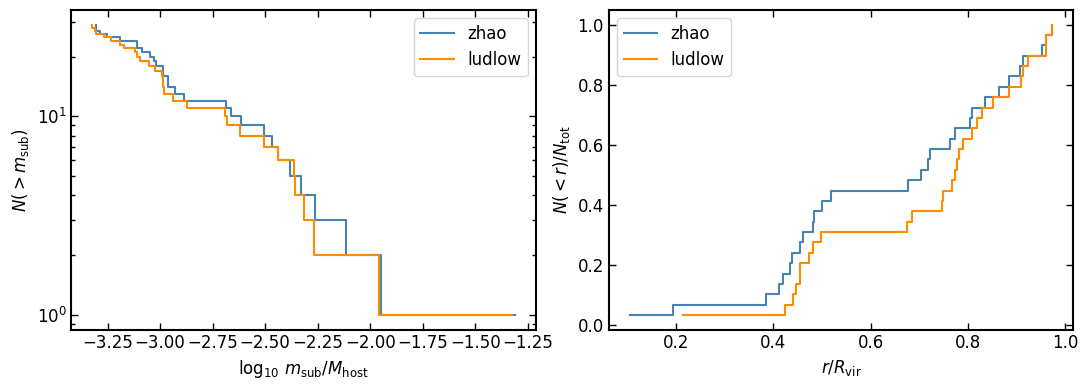

In [8]:
regime = 'artificial'
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for m in models:
    t = T[m]
    ms = t.shmf_z0[regime][:, 0]
    ms = np.sort(ms[np.isfinite(ms)])[::-1]
    ax[0].step(np.log10(ms / t.mass[0, 0]), np.arange(1, ms.size + 1), where='post', color=colors[m], label=m)

    mask = t.regime_masks[regime][:, 0]
    r = np.sort(t.rmags_stitched[mask, 0] / t.VirialRadius[0, 0])
    ax[1].step(r, np.arange(1, r.size + 1) / r.size, where='post', color=colors[m], label=m)

ax[0].set_yscale('log')
ax[0].set_xlabel(r'$\log_{10}\, m_{\rm sub}/M_{\rm host}$')
ax[0].set_ylabel(r'$N(>m_{\rm sub})$')
ax[1].set_xlabel(r'$r/R_{\rm vir}$')
ax[1].set_ylabel(r'$N(<r)/N_{\rm tot}$')
for a in ax: a.legend()
plt.tight_layout()
# plt.savefig('../../figures/ludlow_host_shmf_radial.pdf', bbox_inches='tight')  # uncomment to save
plt.show()